<a href="https://colab.research.google.com/github/shawn-west/Problem-Set-5/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1.1: The data

In [2]:
import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.optimize import brentq
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)
n = 6000

# Real predictors
income = rng.lognormal(np.log(65000), 0.45, n)
dti = rng.beta(2, 5, n)
credit_history = rng.uniform(1, 30, n)
prior_delinquencies = rng.poisson(0.5, n)
loan_amount = rng.lognormal(np.log(20000), 0.5, n)

# Irrelevant predictors
noise_1 = rng.normal(0, 1, n)
noise_2 = rng.normal(0, 1, n)
noise_3 = rng.normal(0, 1, n)

# True relationship with default
risk = (
    -0.7 * np.log(income / 65000)
    + 2.5 * dti
    - 0.04 * credit_history
    + 0.6 * prior_delinquencies
    + 0.3 * np.log(loan_amount / 20000)
)

# Set expected default prevalence to 7%
intercept = brentq(
    lambda b: expit(b + risk).mean() - 0.07,
    -10, 0
)

prob_default = expit(intercept + risk)
default = rng.binomial(1, prob_default)

# Create DataFrame
loans = pd.DataFrame({
    "income": income,
    "dti": dti,
    "credit_history": credit_history,
    "prior_delinquencies": prior_delinquencies,
    "loan_amount": loan_amount,
    "noise_1": noise_1,
    "noise_2": noise_2,
    "noise_3": noise_3,
    "default": default
})

# Split before inspecting the data
X = loans.drop(columns="default")
y = loans["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Test observations:", len(X_test))
print("Test default rate:", round(y_test.mean(), 4))
print("Test defaults:", y_test.sum())

X_test.head()

Test observations: 1800
Test default rate: 0.0744
Test defaults: 134


,income,dti,credit_history,prior_delinquencies,loan_amount,noise_1,noise_2,noise_3
5278,53321.904615,0.096558,14.785543,0,15894.860610,0.322578,0.745535,-0.017609
3721,88923.159532,0.126050,4.476170,0,21971.788346,-0.967083,0.813448,2.208965
3769,91110.938588,0.029810,9.245638,1,23066.323005,-0.448069,1.664902,0.345444
61,55906.967041,0.111606,17.424701,1,12120.372372,0.060843,-0.081267,-0.809689
1017,57463.763112,0.056677,8.305958,0,19223.055427,-0.764929,-0.321395,-0.016198


I created 6,000 fake loan applications with a default rate around 7%. I used income, debt-to-income ratio, credit history, prior delinquencies, and loan amount to figure out the chances of someone defaulting. I also threw in three random variables that don't actually affect default.

I made it so people with more debt, more delinquencies, and bigger loans were more likely to default, while higher income and longer credit history lowered that risk. I split the data before looking at anything so I could test how well my model works on new applications.

### Step 1.2: The null model

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="constant", constant=0)
baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_test)

print("Baseline accuracy:", accuracy_score(y_test, y_pred))

Baseline accuracy: 0.9255555555555556


### Step 2.1: Logistic regression, then penalised

In [4]:
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score
import numpy as np
import pandas as pd

# Regular logistic regression
logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
)

# LASSO logistic regression
lasso = make_pipeline(
    StandardScaler(),
    LogisticRegressionCV(
        Cs=np.logspace(-3, 2, 20),
        cv=5,
        penalty="l1",
        solver="saga",
        scoring="roc_auc",
        max_iter=5000,
        random_state=42
    )
)

# Ridge logistic regression
ridge = make_pipeline(
    StandardScaler(),
    LogisticRegressionCV(
        Cs=np.logspace(-3, 2, 20),
        cv=5,
        penalty="l2",
        solver="lbfgs",
        scoring="roc_auc",
        max_iter=5000
    )
)

for model in [logistic, lasso, ridge]:
    model.fit(X_train, y_train)

In [5]:
for name, model in [
    ("Logistic", logistic),
    ("LASSO", lasso),
    ("Ridge", ridge)
]:
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print(name)
    print("Test accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Test ROC AUC:", round(roc_auc_score(y_test, probabilities), 4))
    print()

Logistic
Test accuracy: 0.925
Test ROC AUC: 0.7069

LASSO
Test accuracy: 0.925
Test ROC AUC: 0.7065

Ridge
Test accuracy: 0.925
Test ROC AUC: 0.7068



In [6]:
coefficients = pd.DataFrame({
    "feature": X_train.columns,
    "LASSO": lasso.named_steps["logisticregressioncv"].coef_[0],
    "Ridge": ridge.named_steps["logisticregressioncv"].coef_[0]
})

print(coefficients)

removed = coefficients.loc[
    coefficients["LASSO"] == 0, "feature"
].tolist()

noise_features = {"noise_1", "noise_2", "noise_3"}
real_features = set(X_train.columns) - noise_features

print("LASSO removed:", removed)
print("Noise features removed:", len(set(removed) & noise_features), "out of 3")
print("Real features removed:", len(set(removed) & real_features), "out of 5")

               feature     LASSO     Ridge
0               income -0.438165 -0.463318
1                  dti  0.406591  0.422642
2       credit_history -0.191800 -0.214476
3  prior_delinquencies  0.449734  0.463566
4          loan_amount  0.195160  0.212798
5              noise_1  0.000000 -0.005333
6              noise_2  0.000000  0.000020
7              noise_3  0.000000  0.005207
LASSO removed: ['noise_1', 'noise_2', 'noise_3']
Noise features removed: 3 out of 3
Real features removed: 0 out of 5


LASSO removed all 3 random features without getting rid of any real ones, which is pretty much what I wanted. Ridge kept everything but made the coefficients smaller. I would use LASSO when I want to remove unnecessary features and Ridge when I think most of my features are useful.

Even though LASSO did a good job selecting features, none of the models beat my baseline accuracy of 92.56% which shows that removing noise doesn't automatically make a model better at predicting defaults.

### Step 2.2: A model that is not linear

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance

rf = RandomForestClassifier(
    n_estimators=500,
    oob_score=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_predictions = rf.predict(X_test)
rf_probabilities = rf.predict_proba(X_test)[:, 1]

print("OOB accuracy:", round(rf.oob_score_, 4))
print("Test accuracy:", round(accuracy_score(y_test, rf_predictions), 4))
print("Test ROC AUC:", round(roc_auc_score(y_test, rf_probabilities), 4))

OOB accuracy: 0.925
Test accuracy: 0.9244
Test ROC AUC: 0.6724


In [8]:
# Built-in MDI importance
mdi = rf.feature_importances_

# Permutation importance on the test set
perm = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

importance_table = pd.DataFrame({
    "feature": X_test.columns,
    "MDI": mdi,
    "Permutation": perm.importances_mean
})

print(importance_table.sort_values("Permutation", ascending=False))

               feature       MDI  Permutation
3  prior_delinquencies  0.051258     0.075420
1                  dti  0.150442     0.049109
0               income  0.141540     0.036356
2       credit_history  0.136470     0.022924
4          loan_amount  0.133432     0.011826
7              noise_3  0.132282     0.010098
5              noise_1  0.129339     0.009366
6              noise_2  0.125236    -0.011637


My random forest got 92.44% accuracy and 0.6724 ROC AUC, so logistic regression did better. OOB accuracy was 92.50%, which was close to the test score since both use unseen data. A big gap would make me question the model.

MDI ranked the noise features pretty high because they had more possible splits, but permutation showed they barely helped. Income also shows that importance isn't the same as effect. It helps predict default, but rejecting a loan won't change someone's income.

### Step 3.1: Beyond accuracy

In [9]:
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1:", round(f1_score(y_test, y_pred), 4))
print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR AUC (Average Precision):", round(average_precision_score(y_test, y_prob), 4))

Confusion Matrix:
 [[1663    3]
 [ 133    1]]
Precision: 0.25
Recall: 0.0075
F1: 0.0145
ROC AUC: 0.6724
PR AUC (Average Precision): 0.1643


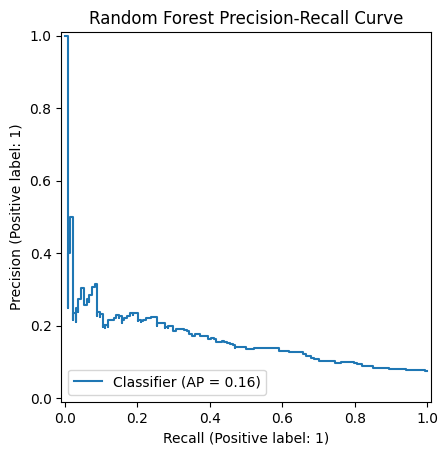

In [10]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Random Forest Precision-Recall Curve")
plt.show()

My random forest got 92.44% accuracy but only caught 1 out of 134 defaults, which is pretty bad. The ROC AUC of 0.6724 makes it look somewhat useful, but the PR AUC of 0.1643 tells a different story. Since only around 7% of applicants default, ROC AUC can hide how many defaults we're missing. The precision-recall curve gives me a better idea of how poorly the model actually catches defaults.

### Step 3.2: Put a price on being wrong

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

probs = rf.predict_proba(X_test)[:, 1]
actual = np.asarray(y_test)
principal = X_test["loan_amount"].to_numpy()

reputation_cost = 500

def loan_cost(threshold, loss_rate=0.60):
    predicted = probs >= threshold

    false_negative = (actual == 1) & (~predicted)
    false_positive = (actual == 0) & predicted

    fn_cost = loss_rate * principal[false_negative].sum()
    fp_cost = (
        0.08 * principal[false_positive].sum()
        + reputation_cost * false_positive.sum()
    )

    return (fn_cost + fp_cost) / len(actual)

# Include all unique prediction cutoffs for an exact search
thresholds = np.unique(np.r_[
    np.linspace(0, 1, 1001),
    probs,
    np.nextafter(probs, 1),
    1.0
])

costs = np.array([loan_cost(t) for t in thresholds])
best_threshold = thresholds[np.argmin(costs)]

print("Default threshold:", 0.5)
print("Optimal threshold:", round(best_threshold, 4))
print("Distance from 0.5:", round(best_threshold - 0.5, 4))
print("Cost at 0.5: $", round(loan_cost(0.5), 2))
print("Minimum cost: $", round(costs.min(), 2))

print("\nConfusion matrix at 0.5:")
print(confusion_matrix(actual, probs >= 0.5))

print("\nConfusion matrix at optimal threshold:")
print(confusion_matrix(actual, probs >= best_threshold))

Default threshold: 0.5
Optimal threshold: 0.172
Distance from 0.5: -0.328
Cost at 0.5: $ 972.51
Minimum cost: $ 889.47

Confusion matrix at 0.5:
[[1663    3]
 [ 132    2]]

Confusion matrix at optimal threshold:
[[1505  161]
 [  94   40]]


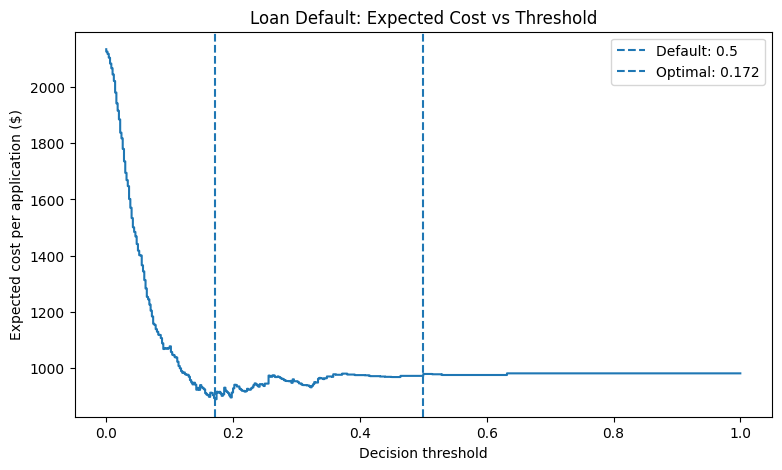

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(thresholds, costs)
plt.axvline(0.5, linestyle="--", label="Default: 0.5")
plt.axvline(best_threshold, linestyle="--",
            label=f"Optimal: {best_threshold:.3f}")

plt.xlabel("Decision threshold")
plt.ylabel("Expected cost per application ($)")
plt.title("Loan Default: Expected Cost vs Threshold")
plt.legend()
plt.show()

In [13]:
results = []

for loss_rate in [0.20, 0.40, 0.60, 0.80, 1.00]:
    scenario_costs = np.array([
        loan_cost(t, loss_rate) for t in thresholds
    ])

    optimal = thresholds[np.argmin(scenario_costs)]

    results.append({
        "Default loss rate": loss_rate,
        "FN / FP cost ratio": round(
            loss_rate * principal.mean() /
            (0.08 * principal.mean() + reputation_cost), 2
        ),
        "Optimal threshold": round(optimal, 4),
        "Cost per application": round(scenario_costs.min(), 2)
    })

results_df = pd.DataFrame(results)
print(results_df)

   Default loss rate  FN / FP cost ratio  Optimal threshold  \
0                0.2                1.96              0.530   
1                0.4                3.91              0.322   
2                0.6                5.87              0.172   
3                0.8                7.83              0.162   
4                1.0                9.79              0.142   

   Cost per application  
0                325.21  
1                631.97  
2                889.47  
3               1101.07  
4               1282.01  


My best threshold was 0.172 instead of 0.5, which lowered the average cost from $972.51 to $889.47 per application. It also helped catch 40 defaults instead of just 2. As missing a default became more expensive, the best threshold dropped from 0.530 to 0.142. My rule for the lender would be to lower the threshold when defaults become more costly, but also consider how many good applicants get rejected.

### Part A — Does the forest actually beat the logistic model?
Prompt: Act as a model risk analyst comparing two credit risk models.

I trained a random forest and a LASSO logistic regression model on loan default data. The forest got 92.44% accuracy and LASSO got 92.50% on the test set.

Can you write Python code to test whether the difference is statistically significant and report the p-value?

Only use NumPy, pandas, and SciPy. Explain each line of code, what assumptions the test makes, and give me a short conclusion I can share with the head of risk.

In [14]:
import numpy as np
from scipy.stats import binomtest, chi2

forest_pred = rf.predict(X_test)
lasso_pred = lasso.predict(X_test)
actual = np.asarray(y_test)

forest_right = forest_pred == actual
lasso_right = lasso_pred == actual

# Discordant predictions
b = np.sum(forest_right & ~lasso_right)
c = np.sum(~forest_right & lasso_right)
n = b + c

# Choose the test based on discordant count
if n == 0:
    test_name = "Exact McNemar (no discordant rows)"
    p_value = 1.0
elif n < 25:
    test_name = "Exact McNemar"
    p_value = binomtest(b, n, 0.5).pvalue
else:
    test_name = "Continuity-corrected McNemar"
    statistic = (abs(b - c) - 1) ** 2 / n
    p_value = chi2.sf(statistic, df=1)

print("b (forest right, LASSO wrong):", b)
print("c (forest wrong, LASSO right):", c)
print("b + c:", n)
print("Test:", test_name)
print("p-value:", p_value)

b (forest right, LASSO wrong): 2
c (forest wrong, LASSO right): 3
b + c: 5
Test: Exact McNemar
p-value: 1.0


####Results:
I used exact McNemar's test because both models predicted the same applicants and only 5 predictions differed. The forest got 2 right that LASSO missed, while LASSO got 3 right that the forest missed. With a p-value of 1.0, there's no significant difference, so my original conclusion still stands: the forest isn't worth the extra complexity based on these results.

One limitation is that accuracy doesn't consider loan losses. Comparing cost or PR-AUC using paired test rows would be more useful for the lender.

### Part B — Is your Phase 3 threshold valid?

Prompt: Act as a model risk analyst reviewing a loan default prediction model.

I trained a random forest on 6,000 loan applications with around 7% default prevalence. My model got a ROC AUC of 0.6724 and a PR AUC of 0.1643. I also found that my best cost-based threshold was 0.172 instead of 0.5.

Can you write Python code to check whether my predicted probabilities are calibrated? Include a reliability diagram, Brier score and its decomposition, Platt scaling, and isotonic regression.

Use scikit-learn, NumPy, and Matplotlib. Explain how a model can have a decent AUC but still give inaccurate probabilities.

Finally, tell me whether I should keep my threshold of 0.172 or calculate a new one after calibration.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, confusion_matrix
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

X_fit, X_hold, y_fit, y_hold = train_test_split(
    X_train, y_train, test_size=0.4,
    stratify=y_train, random_state=42
)

X_cal, X_val, y_cal, y_val = train_test_split(
    X_hold, y_hold, test_size=0.5,
    stratify=y_hold, random_state=43
)

rf_cal = RandomForestClassifier(
    n_estimators=500, oob_score=True,
    bootstrap=True, random_state=42, n_jobs=-1
)
rf_cal.fit(X_fit, y_fit)

p_cal = rf_cal.predict_proba(X_cal)[:, 1]
p_val = rf_cal.predict_proba(X_val)[:, 1]
p_test = rf_cal.predict_proba(X_test)[:, 1]

# Platt scaling: fit a sigmoid to log-odds
def logit_scores(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

platt = LogisticRegression(max_iter=1000)
platt.fit(logit_scores(p_cal), y_cal)

isotonic = IsotonicRegression(out_of_bounds="clip")
isotonic.fit(p_cal, y_cal)

probabilities = {
    "Original": (p_val, p_test),
    "Platt": (
        platt.predict_proba(logit_scores(p_val))[:, 1],
        platt.predict_proba(logit_scores(p_test))[:, 1]
    ),
    "Isotonic": (
        isotonic.predict(p_val),
        isotonic.predict(p_test)
    )
}

for name, (_, p) in probabilities.items():
    print(name, "Test Brier score:",
          round(brier_score_loss(y_test, p), 5))


Original Test Brier score: 0.06768
Platt Test Brier score: 0.06695
Isotonic Test Brier score: 0.06843


Original: Reliability=0.00077, Resolution=0.00202, Uncertainty=0.06890, Approx. Brier=0.06765, Smallest bin=208
Platt: Reliability=0.00021, Resolution=0.00202, Uncertainty=0.06890, Approx. Brier=0.06709, Smallest bin=208
Isotonic: Reliability=0.00026, Resolution=0.00142, Uncertainty=0.06890, Approx. Brier=0.06774, Smallest bin=140


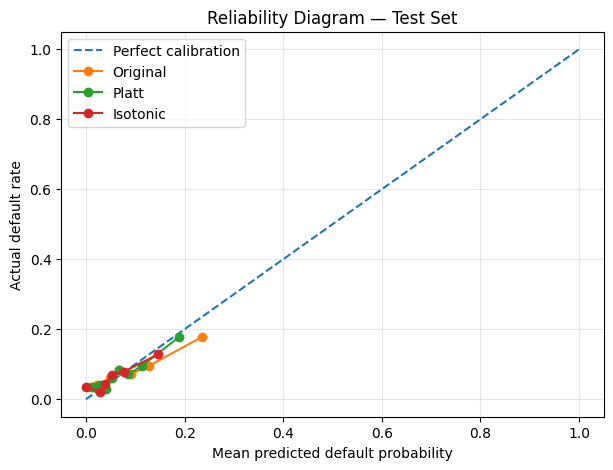

In [16]:
def reliability_stats(y, p, bins=8):
    y = np.asarray(y)
    edges = np.unique(np.quantile(p, np.linspace(0, 1, bins + 1)))
    groups = np.searchsorted(edges[1:-1], p, side="right")

    counts, means, observed = [], [], []

    for i in range(len(edges) - 1):
        mask = groups == i
        if mask.sum() == 0:
            continue
        counts.append(mask.sum())
        means.append(p[mask].mean())
        observed.append(y[mask].mean())

    counts = np.array(counts)
    means = np.array(means)
    observed = np.array(observed)
    weights = counts / counts.sum()
    prevalence = y.mean()

    reliability = np.sum(weights * (means - observed) ** 2)
    resolution = np.sum(weights * (observed - prevalence) ** 2)
    uncertainty = prevalence * (1 - prevalence)

    return means, observed, counts, reliability, resolution, uncertainty


plt.figure(figsize=(7, 5))
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")

for name, (_, p) in probabilities.items():
    means, observed, counts, rel, res, unc = reliability_stats(y_test, p)
    plt.plot(means, observed, marker="o", label=name)
    print(f"{name}: Reliability={rel:.5f}, "
          f"Resolution={res:.5f}, Uncertainty={unc:.5f}, "
          f"Approx. Brier={rel - res + unc:.5f}, "
          f"Smallest bin={counts.min()}")

plt.xlabel("Mean predicted default probability")
plt.ylabel("Actual default rate")
plt.title("Reliability Diagram — Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [17]:
def cost(y, p, principal, threshold):
    y = np.asarray(y)
    principal = np.asarray(principal)
    declined = p >= threshold

    fn = (y == 1) & ~declined
    fp = (y == 0) & declined

    return (
        0.60 * principal[fn].sum()
        + 0.08 * principal[fp].sum()
        + 500 * fp.sum()
    ) / len(y)


def best_threshold(y, p, principal):
    candidates = np.unique(
        np.r_[0, p, np.nextafter(p, 1), 1]
    )
    costs = np.array([
        cost(y, p, principal, t) for t in candidates
    ])
    return candidates[np.argmin(costs)]


for name, (pv, pt) in probabilities.items():
    threshold = best_threshold(
        y_val, pv, X_val["loan_amount"]
    )

    print(f"\n{name}")
    print("Validation-selected threshold:", round(threshold, 4))
    print("Test cost at threshold:",
          round(cost(y_test, pt, X_test["loan_amount"], threshold), 2))
    print("Test cost at old 0.172 threshold:",
          round(cost(y_test, pt, X_test["loan_amount"], 0.172), 2))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, pt >= threshold))


Original
Validation-selected threshold: 0.27
Test cost at threshold: 987.85
Test cost at old 0.172 threshold: 933.5
Confusion matrix:
[[1619   47]
 [ 122   12]]

Platt
Validation-selected threshold: 0.2124
Test cost at threshold: 987.85
Test cost at old 0.172 threshold: 1001.16
Confusion matrix:
[[1619   47]
 [ 122   12]]

Isotonic
Validation-selected threshold: 0.1024
Test cost at threshold: 975.64
Test cost at old 0.172 threshold: 975.64
Confusion matrix:
[[1592   74]
 [ 115   19]]


####Results:
My reliability diagram showed that the original probabilities weren't perfectly calibrated. Platt scaling improved the Brier score from 0.06768 to 0.06695, while isotonic made it worse.

My original threshold of 0.172 didn't really survive the calibration check. After Platt scaling, the new threshold was 0.2124. Even though isotonic had a lower test cost, Platt gave me better probability estimates overall, so I'd lean toward using that.

**To: Head of Risk**
**Subject: Loan Default Model Recommendation**

I wouldn't recommend signing off on the random forest for production just yet.

Our baseline got 92.56% accuracy by predicting nobody would default. The random forest actually did slightly worse at 92.44%, and it only caught 1 out of 134 defaults at the default threshold. LASSO performed slightly better at 92.50%, and McNemar's test (p = 1.0) showed no significant difference.

The forest does have some value when we adjust the threshold based on costs. My original threshold of 0.172 lowered expected losses from $972.51 to $889.47 per application. This assumes a 60% loss on defaulted loans, an 8% lost interest margin, and $500 in reputational costs for wrongly rejecting someone.

However, that threshold was chosen using test data, so I wouldn't trust those savings for production. After checking calibration, I'd recommend testing Platt scaling with a threshold of 0.2124, selected on validation data.

**What would change my answer:** If the calibrated model consistently reduced lending losses compared with the baseline on new, untouched data, I'd reconsider approving it.

For now, I'd keep the model in testing rather than put it into production.